In [1]:
import os

import turmoric
from turmoric.image_process import nd2_to_tif
from turmoric.utils import recursively_get_all_filepaths
from turmoric.apply_thresholds import apply_all_thresh

from pathlib import Path

import pandas as pd
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import filters, io
from skimage.segmentation import clear_border
from skimage.morphology import remove_small_objects
from skimage.measure import block_reduce, label, regionprops, regionprops_table
from skimage import exposure
from scipy import ndimage

from turmoric.cell_analysis import apply_regionprops_recursively
from turmoric.utils import organize_files_without_leakage

import seaborn as sns

In [89]:
all_tifs = recursively_get_all_filepaths("/gscratch/cheme/nlsschim/data/cross_species/tifs/all_data/rat/thresholded/p70_female", file_type=".tif")
print(len(all_tifs))

103


In [90]:
props_list = ('area', 'bbox_area', 'centroid', 'convex_area',
              'eccentricity', 'equivalent_diameter', 'euler_number',
              'extent', 'filled_area', 'major_axis_length',
              'minor_axis_length', 'orientation', 'perimeter', 'solidity',
              'feret_diameter_max')

In [91]:
regionprops_dfs = []

for file in all_tifs:
    im = tiff.imread(file)

    label_im = label(im)
    props = regionprops_table(label_im, properties=props_list)

    props_df = pd.DataFrame(props)

    file_name = file.split("/")[-1]
    print(file_name)
    split_filename = file_name.split("_")
    props_df['filename'] = file_name


    props_df["species"] = split_filename[1]
    props_df["age"] = split_filename[3]
    props_df["sex"] = split_filename[4]
    props_df["animal_id"] = split_filename[5]
    props_df["slide_num"] = split_filename[6]
    props_df["slice_id"] = split_filename[7]
    region = split_filename[10][0:-1]
    if "hip" in region:
        region = region[0:3]
    props_df["region"] = region    


    regionprops_dfs.append(props_df)
    

all_regionprops_data = pd.concat(regionprops_dfs)

20230404_rat_nontreated_p70_female_f1_slide12_slice1_60x_denoised_st1_Alexa_488_antibody_otsu_thresh.tif
20230404_rat_nontreated_p70_female_f1_slide12_slice5_60x_denoised_cblm1_Alexa_488_antibody_otsu_thresh.tif
20230417_rat_nontreated_p70_female_f2_slide17_slice1_60x_denoised_st2_Alexa_488_antibody_otsu_thresh.tif
20230404_rat_nontreated_p70_female_f2_slide6_slice3_60x_denoised_hipCA1_Alexa_488_antibody_otsu_thresh.tif
20230404_rat_nontreated_p70_female_f2_slide6_slice3_60x_denoised_hipCA2_Alexa_488_antibody_otsu_thresh.tif
20230403_rat_nontreated_p70_female_f4_slide22_slice4_60x_denoised_cblm1_Alexa_488_antibody_otsu_thresh.tif
20230404_rat_nontreated_p70_female_f1_slide12_slice1_60x_denoised_pl1_Alexa_488_antibody_otsu_thresh.tif
20230403_rat_nontreated_p70_female_f4_slide22_slice2_60x_denoised_thal1_Alexa_488_antibody_otsu_thresh.tif
20230403_rat_nontreated_p70_female_f4_slide22_slice3_60x_denoised_thal3_Alexa_488_antibody_otsu_thresh.tif
20230417_rat_nontreated_p70_female_f2_slide

In [92]:
all_regionprops_data['circularity'] = 4*np.pi*all_regionprops_data.area/all_regionprops_data.perimeter**2
all_regionprops_data['aspect_ratio'] = all_regionprops_data.major_axis_length/all_regionprops_data.minor_axis_length

In [93]:
all_regionprops_data

,area,bbox_area,centroid-0,centroid-1,convex_area,eccentricity,equivalent_diameter,euler_number,extent,filled_area,...,filename,species,age,sex,animal_id,slide_num,slice_id,region,circularity,aspect_ratio
0,277.0,1519.0,44.624549,87.296029,624.0,0.948722,18.779972,1,0.182357,277.0,...,20230404_rat_nontreated_p70_female_f1_slide12_...,rat,p70,female,f1,slide12,slice1,st,0.188163,3.163428
1,520.0,3400.0,65.461538,192.557692,2054.0,0.959046,25.731004,1,0.152941,520.0,...,20230404_rat_nontreated_p70_female_f1_slide12_...,rat,p70,female,f1,slide12,slice1,st,0.064729,3.530451
2,534.0,3360.0,57.926966,371.844569,2367.0,0.738557,26.075082,1,0.158929,534.0,...,20230404_rat_nontreated_p70_female_f1_slide12_...,rat,p70,female,f1,slide12,slice1,st,0.082256,1.483259
3,321.0,1664.0,108.034268,55.386293,755.0,0.956699,20.216575,1,0.192909,321.0,...,20230404_rat_nontreated_p70_female_f1_slide12_...,rat,p70,female,f1,slide12,slice1,st,0.128928,3.435493
4,139.0,640.0,106.323741,412.582734,439.0,0.867903,13.303394,1,0.217188,139.0,...,20230404_rat_nontreated_p70_female_f1_slide12_...,rat,p70,female,f1,slide12,slice1,st,0.162435,2.013153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,308.0,798.0,280.759740,221.558442,547.0,0.930923,19.802974,1,0.385965,308.0,...,20230403_rat_nontreated_p70_female_f4_slide22_...,rat,p70,female,f4,slide22,slice3,cor,0.190975,2.738117
8,240.0,585.0,281.258333,57.520833,466.0,0.939952,17.480775,1,0.410256,240.0,...,20230403_rat_nontreated_p70_female_f4_slide22_...,rat,p70,female,f4,slide22,slice3,cor,0.289409,2.929927
9,213.0,918.0,345.352113,334.093897,639.0,0.619279,16.468152,1,0.232026,213.0,...,20230403_rat_nontreated_p70_female_f4_slide22_...,rat,p70,female,f4,slide22,slice3,cor,0.140381,1.273608
10,327.0,1012.0,396.437309,400.131498,733.0,0.909858,20.404640,1,0.323123,327.0,...,20230403_rat_nontreated_p70_female_f4_slide22_...,rat,p70,female,f4,slide22,slice3,cor,0.145438,2.410101


In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_running_variance_by_animal(df, value_column, animal_id_column='animal_id', 
                                   species_column=None, ax=None):
    """
    Plot variance as a function of number of animals added.
    Each point represents adding all samples from one animal.
    
    Parameters:
    -----------
    df : DataFrame
        Your microglia data
    value_column : str
        The morphological parameter to analyze (e.g., 'area', 'lacunarity')
    animal_id_column : str
        Column containing animal IDs
    species_column : str, optional
        If provided, will color by species
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))
    
    # Get unique animals
    animals = df[animal_id_column].unique()
    
    # Shuffle animals to avoid order bias (optional)
    np.random.shuffle(animals)
    
    running_var = []
    running_std = []
    running_mean = []
    n_animals = []
    cumulative_n_cells = []
    
    all_values = []
    
    for i, animal in enumerate(animals, 1):
        # Add all values from this animal
        animal_values = df[df[animal_id_column] == animal][value_column].values
        all_values.extend(animal_values)
        
        if len(all_values) >= 2:  # Need at least 2 samples for variance
            running_var.append(np.var(all_values, ddof=1))
            running_std.append(np.std(all_values, ddof=1))
            running_mean.append(np.mean(all_values))
            n_animals.append(i)
            cumulative_n_cells.append(len(all_values))
    
    # Plot variance vs number of animals
    ax.plot(n_animals, running_var, linewidth=2, marker='o', markersize=6)
    ax.axhline(np.var(df[value_column].dropna(), ddof=1), 
               color='r', linestyle='--', linewidth=2,
               label=f'Final variance: {np.var(df[value_column].dropna(), ddof=1):.3f}')
    
    ax.set_xlabel('Number of Animals', fontsize=12)
    ax.set_ylabel('Variance', fontsize=12)
    ax.set_title(f'Variance vs Number of Animals - {value_column}', fontsize=14)
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Add secondary x-axis showing cumulative cell count
    ax2 = ax.twiny()
    ax2.set_xlim(ax.get_xlim())
    ax2.set_xlabel('Cumulative Cell Count', fontsize=12)
    
    # Set ticks for secondary axis
    n_ticks = 5
    tick_positions = np.linspace(0, len(n_animals)-1, n_ticks, dtype=int)
    ax2.set_xticks([n_animals[i] for i in tick_positions])
    ax2.set_xticklabels([cumulative_n_cells[i] for i in tick_positions])
    
    return ax

def plot_running_stats_by_animal(df, value_column, animal_id_column='animal_id'):
    """
    Plot both mean, SD, and CV as animals are added.
    """
    fig, axes = plt.subplots(3, 1, figsize=(10, 12))
    
    animals = df[animal_id_column].unique()
    
    running_var = []
    running_std = []
    running_mean = []
    running_cv = []
    n_animals = []
    
    all_values = []
    
    for i, animal in enumerate(animals, 1):
        animal_values = df[df[animal_id_column] == animal][value_column].values
        all_values.extend(animal_values)
        
        if len(all_values) >= 2:
            mean_val = np.mean(all_values)
            std_val = np.std(all_values, ddof=1)
            
            running_mean.append(mean_val)
            running_std.append(std_val)
            running_var.append(np.var(all_values, ddof=1))
            running_cv.append((std_val / mean_val * 100) if mean_val != 0 else 0)
            n_animals.append(i)
    
    # Plot mean
    axes[0].plot(n_animals, running_mean, linewidth=2, marker='o', markersize=5)
    axes[0].axhline(np.mean(df[value_column].dropna()), 
                    color='r', linestyle='--', linewidth=2,
                    label=f'Final: {np.mean(df[value_column].dropna()):.3f}')
    axes[0].set_ylabel('Mean', fontsize=12)
    axes[0].set_title(f'Running Statistics - {value_column}', fontsize=14)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot SD
    axes[1].plot(n_animals, running_std, linewidth=2, marker='o', 
                 markersize=5, color='orange')
    axes[1].axhline(np.std(df[value_column].dropna(), ddof=1), 
                    color='r', linestyle='--', linewidth=2,
                    label=f'Final: {np.std(df[value_column].dropna(), ddof=1):.3f}')
    axes[1].set_ylabel('Standard Deviation', fontsize=12)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Plot CV
    final_cv = (np.std(df[value_column].dropna(), ddof=1) / 
                np.mean(df[value_column].dropna()) * 100)
    axes[2].plot(n_animals, running_cv, linewidth=2, marker='o', 
                 markersize=5, color='green')
    axes[2].axhline(final_cv, color='r', linestyle='--', linewidth=2,
                    label=f'Final: {final_cv:.1f}%')
    axes[2].set_xlabel('Number of Animals', fontsize=12)
    axes[2].set_ylabel('Coefficient of Variation (%)', fontsize=12)
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig, axes

/tmp/ipykernel_2116/1612306821.py:29: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  np.random.shuffle(animals)


<Axes: title={'center': 'Variance vs Number of Animals - area'}, xlabel='Number of Animals', ylabel='Variance'>

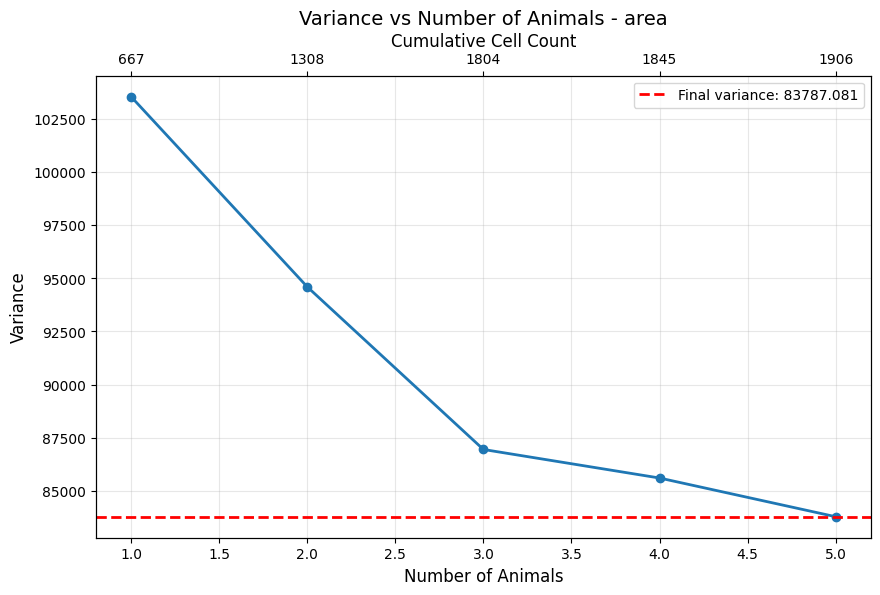

In [94]:
plot_running_variance_by_animal(
    df=all_regionprops_data,
    value_column='area',
    animal_id_column='slice_id'
)

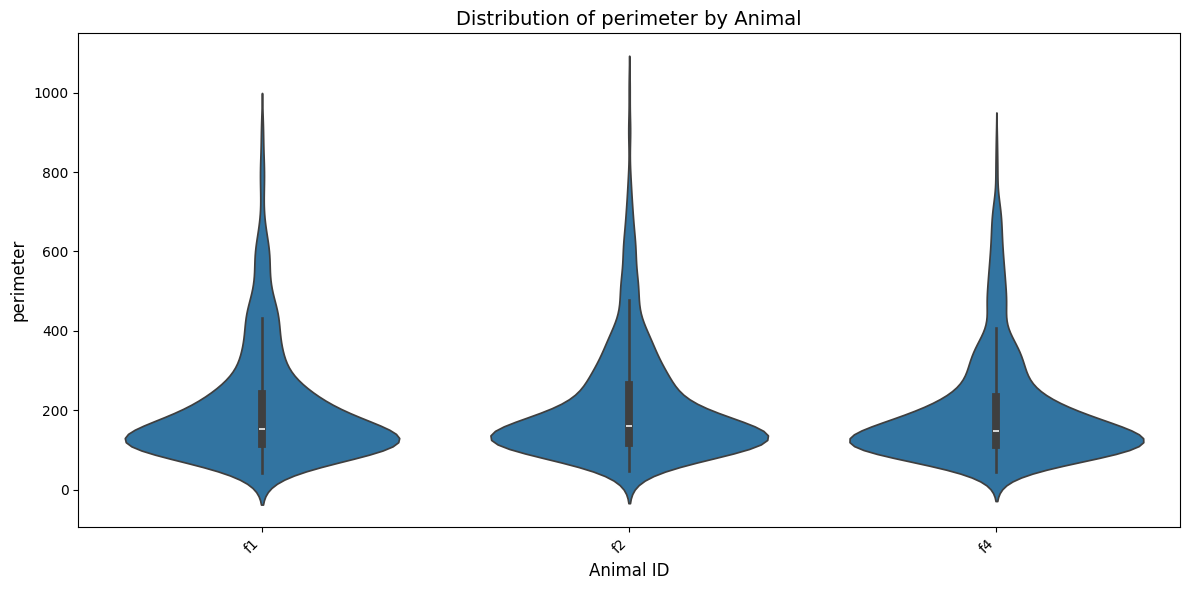

In [95]:
def plot_violin_by_animal(df, value_column='area', animal_id_column='animal_id',
                          figsize=(12, 6)):
    """
    Create violin plot showing distribution for each animal.
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    sns.violinplot(data=df, x=animal_id_column, y=(value_column), ax=ax)
    
    ax.set_xlabel('Animal ID', fontsize=12)
    ax.set_ylabel(value_column, fontsize=12)
    ax.set_title(f'Distribution of {value_column} by Animal', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    return fig, ax

# Usage
plot_violin_by_animal(all_regionprops_data, value_column='perimeter', animal_id_column='animal_id')
plt.show()

In [86]:
import random

def plot_variance_multiple_orders(df, value_column, animal_id_column='animal_id',
                                  species_column='species', n_shuffles=10,
                                  figsize=(14, 6)):
    """
    Show mean variance accumulation across random orderings with std shading.
    """
    species_list = df[species_column].unique()

    fig, axes = plt.subplots(1, len(species_list), figsize=figsize, sharey=True)
    if len(species_list) == 1:
        axes = [axes]

    for idx, species in enumerate(species_list):
        species_df = df[df[species_column] == species]
        animals = list(species_df[animal_id_column].unique())
        n_animals_total = len(animals)

        all_shuffle_vars = np.full((n_shuffles, n_animals_total), np.nan)

        for shuffle_i in range(n_shuffles):
            shuffled_animals = random.sample(animals, len(animals))
            all_values = []

            for i, animal in enumerate(shuffled_animals):
                animal_values = species_df[species_df[animal_id_column] == animal][value_column].values
                all_values.extend(animal_values)

                if len(all_values) >= 2:
                    all_shuffle_vars[shuffle_i, i] = np.var(all_values, ddof=1)

        x = np.arange(1, n_animals_total + 1)
        mean_vars = np.nanmean(all_shuffle_vars, axis=0)
        std_vars = np.nanstd(all_shuffle_vars, axis=0)
        valid_mask = ~np.isnan(mean_vars)

        axes[idx].plot(x[valid_mask], mean_vars[valid_mask],
                       color='blue', linewidth=2.5, label='Mean')
        axes[idx].fill_between(x[valid_mask],
                                mean_vars[valid_mask] - std_vars[valid_mask],
                                mean_vars[valid_mask] + std_vars[valid_mask],
                                alpha=0.3, color='blue', label='± 1 SD')

        final_var = np.var(species_df[value_column].dropna(), ddof=1)
        axes[idx].axhline(final_var, color='red', linestyle='--', linewidth=2,
                          label=f'Final: {final_var:.2f}')

        axes[idx].set_xlabel('Number of Animals', fontsize=11)
        if idx == 0:
            axes[idx].set_ylabel('Variance', fontsize=11)
        axes[idx].set_title(f'{species}\n(n={n_animals_total} animals)', fontsize=12)
        axes[idx].legend(fontsize=9)
        axes[idx].grid(True, alpha=0.3)

    plt.suptitle(f'Variance Accumulation - {value_column}\n({n_shuffles} random orderings)',
                 fontsize=14)
    plt.tight_layout()

    return fig, axes

(<Figure size 1400x600 with 1 Axes>,
 [<Axes: title={'center': 'rat\n(n=102 animals)'}, xlabel='Number of Animals', ylabel='Variance'>])

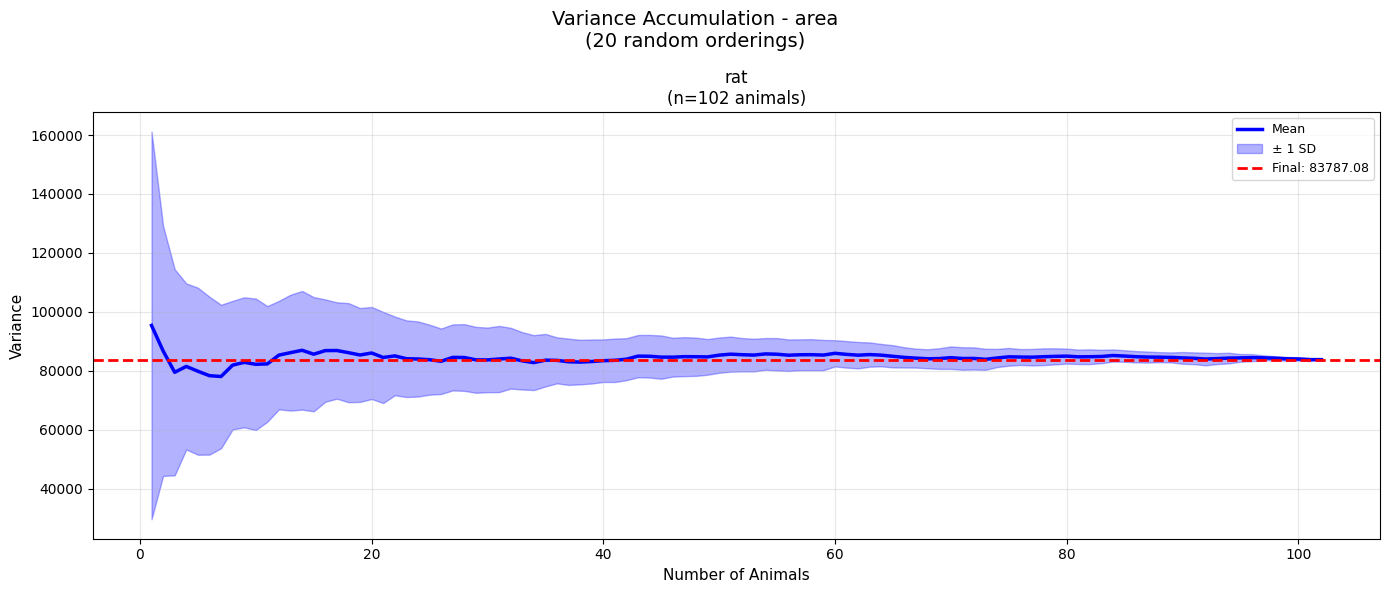

In [96]:
plot_variance_multiple_orders(df=all_regionprops_data, value_column="area", n_shuffles=20, animal_id_column="filename")

In [97]:
all_regionprops_data.to_csv("p70_female_rat_regionprops.csv", index=False)